# Modelagem com MLflow

Mesma base (`nuvem_fraud_dataset_pos_eda_v2.csv`) e mesmo split temporal do notebook 2. As variáveis entram de forma incremental em uma **regressão logística**; no passo final, um **LightGBM** é treinado com a mesma informação. Cada modelo é registrado como um run no MLflow, com as métricas por base (treino, validação e teste):

* `pr_auc`, `roc_auc`, `ks`
* `recall_at_0.05`, `recall_at_0.1`: recall bloqueando score ≥ 0,05 e ≥ 0,1
* `total_cost`: custo operacional (R$) da decisão de bloqueio, via `utils.pnl.decision_pnl`

Servidor de tracking local (rodar na raiz do projeto antes do notebook):

```bash
mlflow server --backend-store-uri sqlite:///mlflow.db --artifacts-destination ./mlartifacts --host 127.0.0.1 --port 5000
```

In [1]:
import sys

import lightgbm as lgb
import mlflow
import mlflow.lightgbm
import mlflow.sklearn
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

sys.path.append("../")

from utils.metrics import classification_metrics
from utils.pnl import decision_pnl, optimal_threshold, threshold_cost_curve
from utils.woe import WoEEncoder

import warnings

warnings.filterwarnings("ignore")

In [2]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("nuvemshop-fraude")

<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1791777698885, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1791777698885, lifecycle_stage='active', name='nuvemshop-fraude', tags={}, trace_location=None, workspace='default'>

In [3]:
df = pd.read_csv("../data/nuvem_fraud_dataset_pos_eda_v2.csv", sep=";", index_col=0)
df["created_at"] = pd.to_datetime(df["created_at"], utc=True)

## Split temporal

Mesmo esquema do notebook 2: um mês de warmup (para as features de histórico), gaps de um mês entre as bases para simular a maturação do chargeback.

In [4]:
df["ym"] = df["created_at"].dt.strftime("%Y-%m")
conds = [
    df.ym < "2019-02",
    df.ym.between("2019-02", "2020-04"),
    df.ym == "2020-05",
    df.ym.between("2020-06", "2020-08"),
    df.ym == "2020-09",
    df.ym >= "2020-10",
]
df["split"] = np.select(
    conds,
    ["warmup", "train", "gap1", "valid", "gap2", "test"],
    default="unassigned",
)
df.groupby("split")["is_fraud"].agg(["size", "sum", "mean"])

,size,sum,mean
split,,,
gap1,13494,81,0.006003
gap2,12793,69,0.005394
test,51557,171,0.003317
train,203934,1159,0.005683
valid,48135,203,0.004217
warmup,9694,99,0.010213


In [5]:
target = "is_fraud"

train = df[df["split"] == "train"].copy()
valid = df[df["split"] == "valid"].copy()
test = df[df["split"] == "test"].copy()

splits = {"train": train, "valid": valid, "test": test}

## Avaliação

Para cada base, métricas de ranking, recall nos thresholds fixos 0,05 e 0,1 e P&L da decisão de bloqueio (`score ≥ threshold`). O threshold de decisão de cada modelo é passado explicitamente.

In [6]:
pnl_params = {"chargeback_fee": 15.0, "margin": 0.10, "review_cost": 5.0}


def evaluate(y_true, y_score, amount, threshold: float) -> dict[str, float]:
    y = np.asarray(y_true).astype(bool)
    s = np.asarray(y_score, dtype=float)
    pnl = decision_pnl(y, s >= threshold, amount, **pnl_params)
    return {
        **{k: v for k, v in classification_metrics(y, s).items() if k in ("pr_auc", "roc_auc", "ks")},
        "recall_at_0.05": (y & (s >= 0.05)).sum() / max(y.sum(), 1),
        "recall_at_0.1": (y & (s >= 0.1)).sum() / max(y.sum(), 1),
        **{k: pnl[k] for k in ("block_rate", "recall", "precision", "fn_cost", "fp_cost",
                               "total_cost", "savings_vs_approve_all")},
    }


def evaluate_splits(scores: dict[str, np.ndarray], threshold: float) -> pd.DataFrame:
    return pd.DataFrame(
        {name: evaluate(data[target], scores[name], data["amount"], threshold)
         for name, data in splits.items()}
    ).T


def log_split_metrics(metrics: pd.DataFrame) -> None:
    mlflow.log_metrics(
        {f"{split}_{metric}": float(value)
         for split, row in metrics.iterrows() for metric, value in row.items()}
    )

# Modelo 0 — regra `amount > 200`

Bloqueia toda transação acima de R$ 200. O score é a própria flag (0 ou 1), então o threshold de decisão é 1 e `recall_at_0.05` = `recall_at_0.1` = recall da regra.

In [7]:
amount_cutoff = 200

for data in splits.values():
    data["high_amount"] = data["amount"].gt(amount_cutoff).astype(int)

rule_scores = {name: data["high_amount"].to_numpy() for name, data in splits.items()}
rule_metrics = evaluate_splits(rule_scores, threshold=1.0)

with mlflow.start_run(run_name="regra_amount_gt_200"):
    mlflow.set_tag("model_type", "rule")
    mlflow.log_params({"rule": f"amount > {amount_cutoff}", "decision_threshold": 1.0, **pnl_params})
    log_split_metrics(rule_metrics)

rule_metrics

🏃 View run regra_amount_gt_200 at: http://127.0.0.1:5000/#/experiments/1/runs/2f2f6b9601bc4d9491b000494d56de3c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,recall,precision,fn_cost,fp_cost,total_cost,savings_vs_approve_all
train,0.066542,0.855015,0.710029,0.755824,0.755824,0.049830,0.755824,0.086204,11632.21,445886.200,457518.410,153797.130
valid,0.048390,0.840090,0.680180,0.724138,0.724138,0.046827,0.724138,0.065217,2574.55,99210.141,101784.691,6768.879
test,0.034347,0.824941,0.649882,0.695906,0.695906,0.048180,0.695906,0.047907,2038.59,113942.594,115981.184,-28334.484


# Variáveis

Todas as variáveis são criadas aqui; cada passo da modelagem escolhe um subconjunto. Quando o tratamento difere entre os modelos, a regressão logística recebe a versão transformada e o LightGBM a versão original:

| Variável | Regressão logística | LightGBM |
|---|---|---|
| `amount > 200` | flag `high_amount` | flag `high_amount` |
| vertical (3 faixas de risco) | WoE (`vertical_group_woe`) | categórica nativa (`vertical_group`) |
| madrugada (22h–03h UTC) | flag `night` | flag `night` |
| velocidade 1h | `txns_prev_1h` | `txns_prev_1h` |
| valor / mediana 30d do cliente | `log` + flag de ausência | razão original (nulos nativos) |

## Vertical

Agrupada em três faixas de risco (mesmos grupos dos notebooks 1 e 2). O WoE é calculado **somente na base de treino** e reaplicado em validação e teste.

In [8]:
vertical_groups = {
    "vertical_high_risk": ["shopping_net", "grocery_pos", "misc_net"],
    "vertical_medium_risk": ["shopping_pos", "gas_transport", "travel", "misc_pos"],
    "vertical_low_risk": [
        "grocery_net", "entertainment", "personal_care", "kids_pets",
        "food_dining", "health_fitness", "home",
    ],
}

vertical_to_group = {
    vertical: group
    for group, verticals in vertical_groups.items()
    for vertical in verticals
}

for data in splits.values():
    data["vertical_group"] = pd.Categorical(
        data["vertical"].map(vertical_to_group), categories=list(vertical_groups)
    )
    assert data["vertical_group"].notna().all(), "Some verticals were not assigned to a group."

encoder = WoEEncoder(["vertical_group"], target=target).fit(train)
for data in splits.values():
    data["vertical_group_woe"] = encoder.transform(data)["vertical_group_woe"]

encoder.tables_["vertical_group"]

is_fraud,n_legit,n_fraud,n_txns,pct_population,fraud_rate,lift,WOE,IV
vertical_group,,,,,,,,
vertical_high_risk,45020,675,45695,0.224068,0.014772,2.599210,0.963833,0.347034
vertical_medium_risk,57022,278,57300,0.280973,0.004852,0.853682,-0.158530,0.006536
vertical_low_risk,100733,206,100939,0.494959,0.002041,0.359099,-1.026680,0.327337


## Madrugada

Flag `night` para transações entre 22h e 03h (UTC), mesma definição do notebook 2.

In [9]:
night_hours = [22, 23, 0, 1, 2, 3]

for data in splits.values():
    data["night"] = data["created_at"].dt.hour.isin(night_hours).astype(int)

train.groupby("night")[target].agg(["size", "mean"])

,size,mean
night,,
0,156167,0.001005
1,47767,0.020977


## Velocidade de 1h

`txns_prev_1h`: número de transações do cliente na hora anterior (janela `[t - 1h, t)`, sem a transação corrente). Contagem pequena (0 a 8, sem nulos) e com taxa de fraude crescente — entra sem transformação.

In [10]:
train.groupby(train["txns_prev_1h"].clip(upper=4))[target].agg(["size", "mean"])

,size,mean
txns_prev_1h,,
0,170434,0.003708
1,29084,0.010693
2,3837,0.033620
3,489,0.112474
4,90,0.355556


## Valor sobre a mediana de 30 dias do cliente

`amount_to_customer_median_ratio_30d`: valor da transação / mediana do cliente nos 30 dias anteriores. Para a regressão logística, mesmo tratamento do notebook 2:

* cauda longa (até ~800x) → `log`
* nulos (cliente sem histórico em 30 dias, ~0,05% da base, mas com taxa de fraude ~10%) recebem log(1) = 0 (neutro) e uma flag de ausência

A relação com a fraude não é linear: a taxa fica estável nos 9 primeiros decis e salta no último (razão > ~3,5x).

In [11]:
ratio_col = "amount_to_customer_median_ratio_30d"

for data in splits.values():
    data["log_amount_median_ratio_30d"] = np.log(data[ratio_col]).fillna(0.0)
    data["amount_median_ratio_30d_missing"] = data[ratio_col].isna().astype(int)

train.groupby(pd.qcut(np.log(train[ratio_col]), 10))[target].agg(["size", "mean"])

,size,mean
amount_to_customer_median_ratio_30d,,
"(-4.639, -2.273]",20393,0.001765
"(-2.273, -1.623]",20392,0.002697
"(-1.623, -0.954]",20392,0.003384
"(-0.954, -0.358]",20392,0.003629
"(-0.358, 0.0]",20394,0.001569
"(0.0, 0.268]",20390,0.001569
"(0.268, 0.537]",20392,0.000638
"(0.537, 0.859]",20392,0.000785
"(0.859, 1.265]",20392,0.001863


# Regressão logística

Uma variável nova por passo:

| Passo | Variável acrescentada | Tratamento |
|---|---|---|
| 1 | `amount > 200` | flag |
| 2 | vertical | WoE |
| 3 | madrugada | flag |
| 4 | velocidade 1h | contagem |
| 5 | valor / mediana 30d do cliente | `log` + flag de ausência |

O threshold de decisão do P&L é o de menor custo na **validação**.

In [12]:
def fit_logreg(features: list[str]) -> LogisticRegression:
    return LogisticRegression().fit(train[features], train[target])


def logreg_coefs(model: LogisticRegression, features: list[str]) -> pd.Series:
    return pd.Series(
        np.append(model.intercept_, model.coef_.ravel()),
        index=["intercept", *features],
        name="coef",
    )


def log_experiment(run_name: str, model, features: list[str], step: int, params: dict) -> pd.DataFrame:
    scores = {name: model.predict_proba(data[features])[:, 1] for name, data in splits.items()}
    curve_valid = threshold_cost_curve(valid[target], scores["valid"], valid["amount"], **pnl_params)
    threshold = optimal_threshold(curve_valid)
    metrics = evaluate_splits(scores, threshold=threshold)

    is_logreg = isinstance(model, LogisticRegression)
    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({"model_type": "logistic_regression" if is_logreg else "lightgbm", "step": step})
        mlflow.log_params({
            "features": ",".join(features),
            "amount_cutoff": amount_cutoff,
            "decision_threshold": threshold,
            **params,
            **pnl_params,
        })
        log_split_metrics(metrics)
        flavor = mlflow.sklearn if is_logreg else mlflow.lightgbm
        flavor.log_model(model, name="model", input_example=train[features].head())

    return metrics


results = {(0, "regra"): rule_metrics}

## Passo 1 — `amount > 200`

Mesma flag da regra como única variável: ordenação idêntica à da regra, mas o score passa a ser uma probabilidade.

In [13]:
logreg_features_1 = ["high_amount"]
logreg_1 = fit_logreg(logreg_features_1)
results[(1, "logreg")] = log_experiment(
    "logreg_amount_gt_200", logreg_1, logreg_features_1, step=1,
    params={f"logreg_{k}": v for k, v in logreg_1.get_params().items()},
)
logreg_coefs(logreg_1, logreg_features_1)

2026/10/12 01:58:27 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run logreg_amount_gt_200 at: http://127.0.0.1:5000/#/experiments/1/runs/935822059c3f432b8830a0942e702515
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept     -6.489853
high_amount    4.112729
Name: coef, dtype: float64

## Passo 2 — vertical (WoE)

Acrescenta a vertical agrupada em três faixas de risco, codificada via WoE.

In [14]:
logreg_features_2 = [*logreg_features_1, "vertical_group_woe"]
logreg_2 = fit_logreg(logreg_features_2)
results[(2, "logreg")] = log_experiment(
    "logreg_amount_gt_200_vertical", logreg_2, logreg_features_2, step=2,
    params={f"logreg_{k}": v for k, v in logreg_2.get_params().items()},
)
logreg_coefs(logreg_2, logreg_features_2)

2026/10/12 01:58:31 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '      high_amount vertical_group_woe\n9694            0           0.963833\n9695            0          -1.026680\n9696            0           0.963833\n9697            0          -1.026680\n9698            0           0.963833' with schema '['high_amount': long (required), 'vertical_group_woe': double (required)]'. Error: Incompatible input types for column vertical_group_woe. Can not safely convert category to float64."). To see the full traceback, set the logging level to DEBUG via `logging.getLogger("mlflow").setLevel(logging.DEBUG)`.


2026/10/12 01:58:35 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run logreg_amount_gt_200_vertical at: http://127.0.0.1:5000/#/experiments/1/runs/76f7f0b907ef4ecc93f2debd79c9f788
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept            -6.342409
high_amount           3.820988
vertical_group_woe    0.466065
Name: coef, dtype: float64

## Passo 3 — madrugada

Acrescenta a flag `night` (22h–03h UTC).

In [15]:
logreg_features_3 = [*logreg_features_2, "night"]
logreg_3 = fit_logreg(logreg_features_3)
results[(3, "logreg")] = log_experiment(
    "logreg_amount_gt_200_vertical_night", logreg_3, logreg_features_3, step=3,
    params={f"logreg_{k}": v for k, v in logreg_3.get_params().items()},
)
logreg_coefs(logreg_3, logreg_features_3)

2026/10/12 01:58:39 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '      high_amount vertical_group_woe  night\n9694            0           0.963833      1\n9695            0          -1.026680      1\n9696            0           0.963833      1\n9697            0          -1.026680      1\n9698            0           0.963833      1' with schema '['high_amount': long (required), 'vertical_group_woe': double (required), 'night': long (required)]'. Error: Incompatible input types for column vertical_group_woe. Can not safely convert category to float64."). To see the full traceback, set the logging level to DEBUG via `logging.getLogger("mlflow").setLevel(logging.DEBUG)`.


2026/10/12 01:58:44 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run logreg_amount_gt_200_vertical_night at: http://127.0.0.1:5000/#/experiments/1/runs/5d7c28426a204b8db8c355e4d48f50cb
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept            -8.103842
high_amount           3.973592
vertical_group_woe    0.245466
night                 2.927245
Name: coef, dtype: float64

## Passo 4 — velocidade 1h

Acrescenta `txns_prev_1h`.

In [16]:
logreg_features_4 = [*logreg_features_3, "txns_prev_1h"]
logreg_4 = fit_logreg(logreg_features_4)
results[(4, "logreg")] = log_experiment(
    "logreg_amount_gt_200_vertical_night_vel_1h", logreg_4, logreg_features_4, step=4,
    params={f"logreg_{k}": v for k, v in logreg_4.get_params().items()},
)
logreg_coefs(logreg_4, logreg_features_4)

2026/10/12 01:58:48 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '      high_amount vertical_group_woe  night  txns_prev_1h\n9694            0           0.963833      1             0\n9695            0          -1.026680      1             1\n9696            0           0.963833      1             1\n9697            0          -1.026680      1             0\n9698            0           0.963833      1             0' with schema '['high_amount': long (required), 'vertical_group_woe': double (required), 'night': long (required), 'txns_prev_1h': long (required)]'. Error: Incompatible input types for column vertical_group_woe. Can not safely convert category to float64."). To see the full traceback, set the logging level to DEBUG via `logging.getLogger("mlflow").setLevel(logging.DEBUG)`.


2026/10/12 01:58:52 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run logreg_amount_gt_200_vertical_night_vel_1h at: http://127.0.0.1:5000/#/experiments/1/runs/542ed593e53d4e7daff1f10dcf17f477
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept            -8.372374
high_amount           3.873388
vertical_group_woe    0.264825
night                 2.845563
txns_prev_1h          1.054151
Name: coef, dtype: float64

## Passo 5 — valor / mediana 30d do cliente

Acrescenta `log` da razão e a flag de ausência.

In [17]:
logreg_features_5 = [*logreg_features_4, "log_amount_median_ratio_30d", "amount_median_ratio_30d_missing"]
logreg_5 = fit_logreg(logreg_features_5)
results[(5, "logreg")] = log_experiment(
    "logreg_amount_gt_200_vertical_night_vel_1h_ratio_30d", logreg_5, logreg_features_5, step=5,
    params={f"logreg_{k}": v for k, v in logreg_5.get_params().items()},
)
logreg_coefs(logreg_5, logreg_features_5)

2026/10/12 01:58:57 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '      high_amount vertical_group_woe  night  txns_prev_1h  \\\n9694            0           0.963833      1             0   \n9695            0          -1.026680      1             1   \n9696            0           0.963833      1             1   \n9697            0          -1.026680      1             0   \n9698            0           0.963833      1             0   \n\n      log_amount_median_ratio_30d  amount_median_ratio_30d_missing  \n9694                    -0.066890                                0  \n9695                    -0.071727                                0  \n9696                     1.164602                                0  \n9697                    -3.888481                                0  \n9698                     0.803572                                0  ' with schema '['high_amount': long

2026/10/12 01:59:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


🏃 View run logreg_amount_gt_200_vertical_night_vel_1h_ratio_30d at: http://127.0.0.1:5000/#/experiments/1/runs/70b1b94afb4a4e4c8c413cfd74e0fbde
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


intercept                         -8.598716
high_amount                        3.954712
vertical_group_woe                 0.279689
night                              3.033429
txns_prev_1h                       1.081080
log_amount_median_ratio_30d       -0.025529
amount_median_ratio_30d_missing    0.299060
Name: coef, dtype: float64

# Modelo final — LightGBM

Mesma informação do passo 5, sem transformações: vertical como categórica nativa e razão sobre a mediana de 30 dias na escala original (nulos tratados nativamente). A relação da razão com a fraude não é linear — o que a regressão logística não captura.

Hiperparâmetros do modelo 4 do notebook 2, com early stopping na validação (pela average precision): as métricas de validação ficam levemente otimistas, **o teste é a referência**.

In [18]:
lgbm_features = ["high_amount", "vertical_group", "night", "txns_prev_1h", ratio_col]

lgbm_params = {
    "n_estimators": 2000,
    "learning_rate": 0.03,
    "num_leaves": 15,
    "min_child_samples": 100,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_lambda": 1.0,
    "random_state": 42,
    "verbose": -1,
}

lgbm = lgb.LGBMClassifier(**lgbm_params).fit(
    train[lgbm_features],
    train[target],
    eval_set=[(valid[lgbm_features], valid[target])],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(100, verbose=False)],
)

results[(6, "lgbm")] = log_experiment(
    "lgbm_amount_gt_200_vertical_night_vel_1h_ratio_30d", lgbm, lgbm_features, step=6,
    params={**{f"lgbm_{k}": v for k, v in lgbm_params.items()}, "lgbm_best_iteration": lgbm.best_iteration_},
)

print(f"Melhor iteração: {lgbm.best_iteration_}")
pd.Series(
    lgbm.booster_.feature_importance(importance_type="gain"),
    index=lgbm_features,
    name="gain",
).sort_values(ascending=False).pipe(lambda s: s / s.sum())

2026/10/12 01:59:07 WARNING mlflow.models.signature: Failed to infer the model signature from the input example. Reason: MlflowException("Failed to enforce schema of data '      high_amount      vertical_group  night  txns_prev_1h  \\\n9694            0  vertical_high_risk      1             0   \n9695            0   vertical_low_risk      1             1   \n9696            0  vertical_high_risk      1             1   \n9697            0   vertical_low_risk      1             0   \n9698            0  vertical_high_risk      1             0   \n\n      amount_to_customer_median_ratio_30d  \n9694                             0.935298  \n9695                             0.930785  \n9696                             3.204646  \n9697                             0.020476  \n9698                             2.233504  ' with schema '['high_amount': long (required), 'vertical_group': string (required), 'night': long (required), 'txns_prev_1h': long (required), 'amount_to_customer_median_ratio_30

2026/10/12 01:59:11 WARNING mlflow.utils.requirements_utils: Failed to run predict on input_example, dependencies introduced in predict are not captured.
ValueError('train and valid dataset categorical_feature do not match.')Traceback (most recent call last):
  File "/home/bruno/nuvemshop_case/.venv/lib/python3.12/site-packages/mlflow/utils/_capture_modules.py", line 170, in load_model_and_predict
    model.predict(input_example, params=params)
  File "/home/bruno/nuvemshop_case/.venv/lib/python3.12/site-packages/mlflow/lightgbm/__init__.py", line 616, in predict
    return self.lgb_model.predict(dataframe)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/bruno/nuvemshop_case/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py", line 1743, in predict
    result = self.predict_proba(
             ^^^^^^^^^^^^^^^^^^^
  File "/home/bruno/nuvemshop_case/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py", line 1773, in predict_proba
    result = super().predict(
          

2026/10/12 01:59:11 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/10/12 01:59:12 WARNING mlflow.models.model: Failed to validate serving input example {
  "dataframe_split": {
    "columns": [
      "h.... Alternatively, you can avoid passing input example and pass model signature instead when logging the model. To ensure the input example is valid prior to serving, please try calling `mlflow.models.predict(model_uri=..., input_data=serving_input, env_manager="uv")` on the model uri and serving input example. A serving input example can be generated from model input example using `mlflow.models.convert_input_example_to_serving_input` function.
Got error: train and valid dataset categorical_feature do not match.


🏃 View run lgbm_amount_gt_200_vertical_night_vel_1h_ratio_30d at: http://127.0.0.1:5000/#/experiments/1/runs/c7cf2bb69c4e4ed68fdec461fb75d35f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Melhor iteração: 101


high_amount                            0.418874
amount_to_customer_median_ratio_30d    0.241420
night                                  0.219634
vertical_group                         0.064406
txns_prev_1h                           0.055666
Name: gain, dtype: float64

# Resumo

In [19]:
labels = {
    (0, "regra"): "0. regra amount > 200",
    (1, "logreg"): "1. logreg amount > 200",
    (2, "logreg"): "2. + vertical",
    (3, "logreg"): "3. + madrugada",
    (4, "logreg"): "4. + velocidade 1h",
    (5, "logreg"): "5. + razão mediana 30d",
    (6, "lgbm"): "6. LightGBM (passo 5)",
}

summary = (
    pd.concat({labels[k]: v for k, v in sorted(results.items())}, names=["modelo", "base"])
    .loc[:, ["pr_auc", "roc_auc", "ks", "recall_at_0.05", "recall_at_0.1", "block_rate",
             "total_cost", "savings_vs_approve_all"]]
)
summary_test = summary.xs("test", level="base")
summary_test

,pr_auc,roc_auc,ks,recall_at_0.05,recall_at_0.1,block_rate,total_cost,savings_vs_approve_all
modelo,,,,,,,,
0. regra amount > 200,0.034347,0.824941,0.649882,0.695906,0.695906,0.048180,115981.184,-28334.484
1. logreg amount > 200,0.034347,0.824941,0.649882,0.695906,0.000000,0.048180,115981.184,-28334.484
2. + vertical,0.054497,0.823349,0.649882,0.660819,0.549708,0.022247,69795.298,17851.402
3. + madrugada,0.115626,0.915981,0.676740,0.549708,0.549708,0.013189,49115.880,38530.820
4. + velocidade 1h,0.206180,0.922474,0.742924,0.567251,0.555556,0.012123,48105.593,39541.107
5. + razão mediana 30d,0.213826,0.925531,0.745668,0.567251,0.555556,0.012084,46815.705,40830.995
6. LightGBM (passo 5),0.400001,0.961967,0.824484,0.654971,0.543860,0.007138,41364.477,46282.223


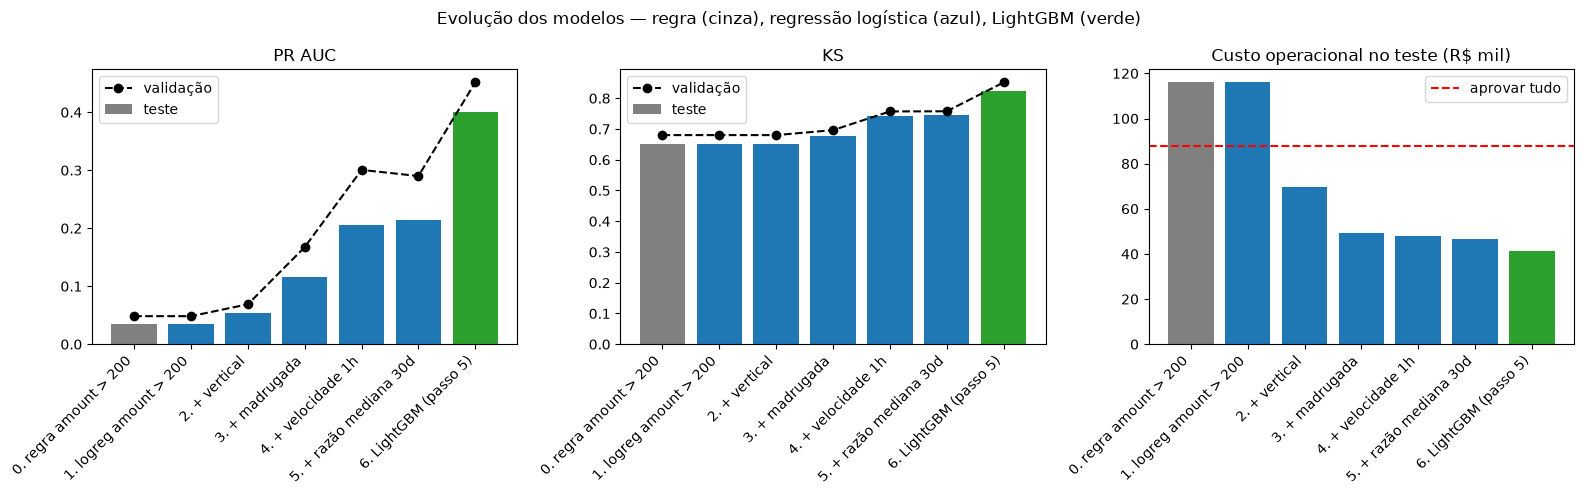

In [20]:
import matplotlib.pyplot as plt

summary_valid = summary.xs("valid", level="base")
x = np.arange(len(summary_test))
colors = ["gray", *["tab:blue"] * 5, "tab:green"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric, title in [(axes[0], "pr_auc", "PR AUC"), (axes[1], "ks", "KS")]:
    ax.bar(x, summary_test[metric], color=colors, label="teste")
    ax.plot(x, summary_valid[metric], "o--", color="black", label="validação")
    ax.set_title(title)
    ax.legend()

axes[2].bar(x, summary_test["total_cost"] / 1e3, color=colors)
approve_all_test = (summary_test["total_cost"] + summary_test["savings_vs_approve_all"]).iloc[0]
axes[2].axhline(approve_all_test / 1e3, color="red", linestyle="--", label="aprovar tudo")
axes[2].set_title("Custo operacional no teste (R$ mil)")
axes[2].legend()

for ax in axes:
    ax.set_xticks(x, summary_test.index, rotation=45, ha="right")

fig.suptitle("Evolução dos modelos — regra (cinza), regressão logística (azul), LightGBM (verde)")
plt.tight_layout()
plt.show()

In [21]:
best_logreg = summary_test.loc[labels[(4, "logreg")]:labels[(5, "logreg")]]["total_cost"].idxmin()
rule, lr, gbm = summary_test.loc[labels[(0, "regra")]], summary_test.loc[best_logreg], summary_test.loc[labels[(6, "lgbm")]]

print(f"""Resumo (base de teste)

Regra amount > 200: PR AUC {rule.pr_auc:.3f}, KS {rule.ks:.3f}, custo R$ {rule.total_cost:,.0f}
  ({rule.savings_vs_approve_all:+,.0f} vs aprovar tudo) — bloqueia {rule.block_rate:.1%} das transações.

Regressão logística: cada variável reduz o custo; vertical e madrugada trazem os maiores ganhos.
  Melhor ({best_logreg}): PR AUC {lr.pr_auc:.3f}, KS {lr.ks:.3f}, custo R$ {lr.total_cost:,.0f}
  ({lr.savings_vs_approve_all:+,.0f} vs aprovar tudo), bloqueando {lr.block_rate:.1%}.
  A razão sobre a mediana de 30d quase não muda a regressão: o efeito se concentra no último decil
  e não é capturado por um termo linear.

LightGBM com as mesmas variáveis: PR AUC {gbm.pr_auc:.3f}, KS {gbm.ks:.3f}, custo R$ {gbm.total_cost:,.0f}
  ({gbm.savings_vs_approve_all:+,.0f} vs aprovar tudo), bloqueando {gbm.block_rate:.1%}.
  Em relação à melhor regressão logística: PR AUC {gbm.pr_auc / lr.pr_auc:.1f}x e
  custo R$ {lr.total_cost - gbm.total_cost:,.0f} menor ({1 - gbm.total_cost / lr.total_cost:.0%}).
""")

Resumo (base de teste)

Regra amount > 200: PR AUC 0.034, KS 0.650, custo R$ 115,981
  (-28,334 vs aprovar tudo) — bloqueia 4.8% das transações.

Regressão logística: cada variável reduz o custo; vertical e madrugada trazem os maiores ganhos.
  Melhor (5. + razão mediana 30d): PR AUC 0.214, KS 0.746, custo R$ 46,816
  (+40,831 vs aprovar tudo), bloqueando 1.2%.
  A razão sobre a mediana de 30d quase não muda a regressão: o efeito se concentra no último decil
  e não é capturado por um termo linear.

LightGBM com as mesmas variáveis: PR AUC 0.400, KS 0.824, custo R$ 41,364
  (+46,282 vs aprovar tudo), bloqueando 0.7%.
  Em relação à melhor regressão logística: PR AUC 1.9x e
  custo R$ 5,451 menor (12%).

